# Day 1: Points



In [15]:
#setup
import requests
import json
import pandas as pd
import os
import configparser
import geopandas as gpd
from shapely.geometry import Point

import matplotlib.pyplot as plt

In [2]:
#set filepaths
project_root = os.path.abspath(os.getcwd())
root = os.path.abspath(os.path.join(os.getcwd(), '..', '..'))
config_file =  os.path.join(root, 'config.cfg')

# geodata for shapefiles
config = configparser.ConfigParser()
config.read(config_file)
gdata_root = config['geodata']['path']

In [ ]:
#get data directly -- timed out, got it through Overpass Turbo instead

overpass_url = "https://overpass-api.de/api/interpreter"

overpass_query = """
[out:json][timeout:180];

rel(65606); map_to_area -> .greater_london;
rel(51800); map_to_area -> .city_of_london;

(
  nwr(area.greater_london)["shop"]["name"~"^(Lidl|Aldi)$", i];
  nwr(area.city_of_london)["shop"]["name"~"^(Lidl|Aldi)$", i];
);

out center tags;
"""

response = requests.get(
    overpass_url,
    params={"data": overpass_query},
    headers={"User-Agent": "30-day-map-challenge (lisa_hornung@gmx.de)"},
)
response.raise_for_status() 
data = response.json()

In [ ]:
# load json
with open("data.json", encoding="utf-8") as f:
    data = json.load(f)

# convert json into dataframe
df_dict = {"id": [], "type": [], "lat": [], "lon": [], "name": [], "shop": []}

for element in data["elements"]:
    df_dict["id"].append(element["id"])
    df_dict["type"].append(element["type"])
    for tag in ["name", "shop"]:
        df_dict[tag].append(element.get("tags", {}).get(tag, ""))
    if element["type"] == "node":
        df_dict["lat"].append(element["lat"])
        df_dict["lon"].append(element["lon"])
    else:
        df_dict["lat"].append(element["center"]["lat"])
        df_dict["lon"].append(element["center"]["lon"])

df = pd.DataFrame.from_dict(df_dict)

# normalise brand name
df["brand"] = df["name"].str.strip().str.title()

# convert into geodataframe
geometry = [Point(xy) for xy in zip(df["lon"].astype(float), df["lat"].astype(float))]
gdf = gpd.GeoDataFrame(df, crs="EPSG:4326", geometry=geometry)

print(gdf["brand"].value_counts())
gdf.head()

brand
Lidl    120
Aldi     61
Name: count, dtype: int64


,id,type,lat,lon,name,shop,brand,geometry
0,1183415035,node,51.514562,-0.474268,Aldi,supermarket,Aldi,POINT (-0.47427 51.51456)
1,2906520923,node,51.535230,-0.483669,Lidl,supermarket,Lidl,POINT (-0.48367 51.53523)
2,13389492734,node,51.545778,-0.476606,Lidl,supermarket,Lidl,POINT (-0.47661 51.54578)
3,13508667350,node,51.549364,-0.479649,Aldi,supermarket,Aldi,POINT (-0.47965 51.54936)
4,1699816075,node,51.360490,-0.310032,Lidl,supermarket,Lidl,POINT (-0.31003 51.36049)


In [13]:
# read London shapefile and reproject to coordinate system to match grid
london = gpd.read_file(os.path.join(gdata_root, 'london-shapefiles\\london-no-river.geojson'))

# load river shapefile
river = gpd.GeoDataFrame.from_file(os.path.join(gdata_root, 'london-shapefiles\\river-thames-clipped.geojson'))

In [25]:
for brand, data in gdf.groupby('brand'):
    print(data)

              id  type        lat       lon  name         shop brand  \
0     1183415035  node  51.514562 -0.474268  Aldi  supermarket  Aldi   
3    13508667350  node  51.549364 -0.479649  Aldi  supermarket  Aldi   
5     9657815966  node  51.375997 -0.223335  Aldi  supermarket  Aldi   
9     8983092414  node  51.372362 -0.118880  Aldi  supermarket  Aldi   
11   14318424601  node  51.437506 -0.375613  Aldi  supermarket  Aldi   
..           ...   ...        ...       ...   ...          ...   ...   
168   1057635166   way  51.575033  0.084437  Aldi  supermarket  Aldi   
170    540747486   way  51.506095  0.106213  Aldi  supermarket  Aldi   
176    589008574   way  51.581645  0.163302  Aldi  supermarket  Aldi   
177    846582231   way  51.597593  0.157855  Aldi  supermarket  Aldi   
179    315187889   way  51.556439  0.248548  Aldi  supermarket  Aldi   

                      geometry  
0    POINT (-0.47427 51.51456)  
3    POINT (-0.47965 51.54936)  
5    POINT (-0.22334 51.37600)  
9  

## Visualise

In [72]:
from pypalettes import load_cmap
from pyfonts import load_google_font
import matplotlib.pyplot as plt

font_r = load_google_font("Open Sans", weight="regular" )
font_b = load_google_font("Open Sans", weight="bold" )
font_title = load_google_font("Questrial")
font_subtitle = load_google_font("Bentham")

In [117]:
gdf["brand"].value_counts()

brand
Lidl    120
Aldi     61
Name: count, dtype: int64

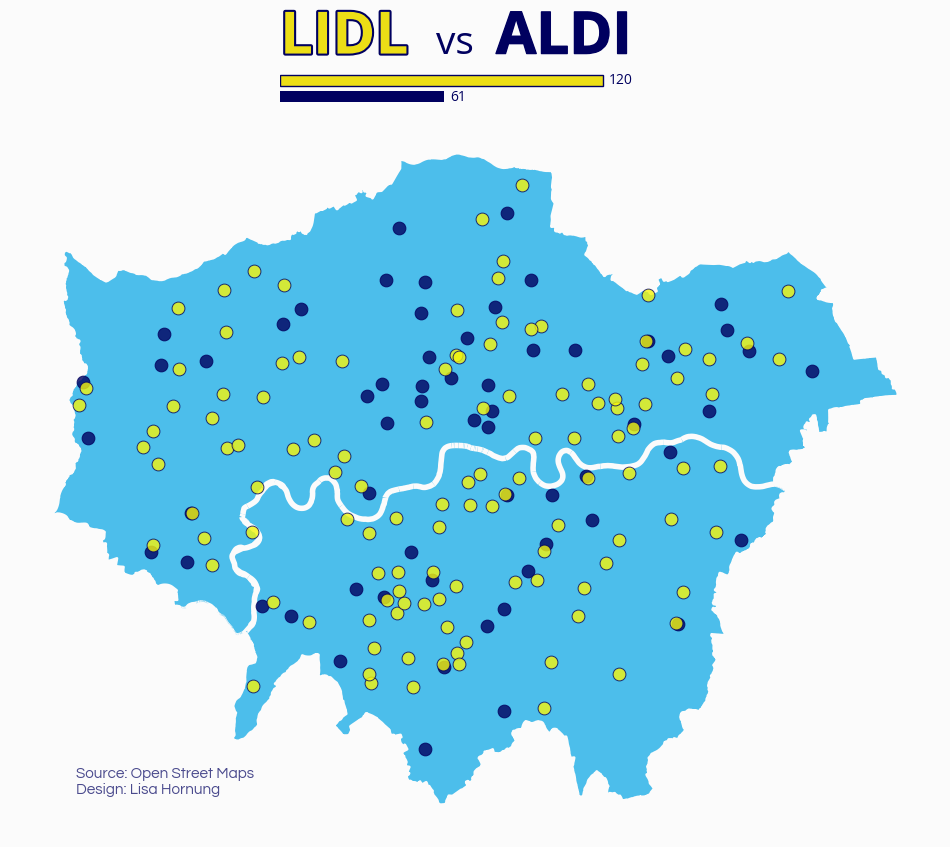

In [153]:
# setup figure  ---------------------------
fig, ax = plt.subplots(figsize=(12, 10))
ax.axis("off")
fig.set_facecolor(bg)

#colours
clrs = { 'Lidl': '#ECDE16', 'Aldi': '#00005F',
         "bg": '#FBFBFB', "london":"#4CBEEB", "river": "#FBFBFB" }

# add london and river for reference  ---------------------------
london.plot(ax=ax, color='#4CBEEB', edgecolor=clrs["river"], linewidth=2, zorder=1)
river.plot(ax=ax, color=clrs["river"], edgecolor=clrs["river"], linewidth=4, zorder=2, alpha=1)

for brand, data in gdf.groupby('brand'):
    color = cPalette[brand]
    label = brand
    data.plot(color=color,
              ax=ax,
              label=label,
              markersize=85,
             edgecolor=clrs["Aldi"],
             linewidth=0.7,
             alpha=0.8,
             zorder=3)

#Text
import matplotlib.patheffects as pe
x = 0.35
y = 0.92
fig.text(x,y , "Lidl".upper(), font=font_b, 
    color=clrs["Lidl"], fontsize=42, fontweight="bold",
    path_effects=[pe.withStroke(linewidth=3, foreground=clrs["Aldi"])])
fig.text(x + 0.13,y, "vs", font=font_r, color=clrs["Aldi"], fontsize=28, )
fig.text(x + 0.18,y , "Aldi".upper(), font=font_b, 
    color=clrs["Aldi"], fontsize=42, fontweight="bold",
    path_effects=[pe.withStroke(linewidth=1, foreground=clrs["Aldi"])])
fig.text(0.18,0.18, "Source: Open Street Maps \nDesign: Lisa Hornung", 
font=font_title, color=clrs["Aldi"], fontsize=11, alpha=0.7)

#Bar chart
ax_bar = fig.add_axes([x, 0.87, 0.31, 0.03])
brands = ["Lidl", "Aldi"]
counts = [120, 61]
ax_bar.barh(brands, counts, color=[clrs["Lidl"], clrs["Aldi"]], edgecolor=[clrs["Aldi"], "none"],
 linewidth=1,height=0.7)
ax_bar.invert_yaxis()          
ax_bar.set_xlim(0, max(counts) * 1.15)
for y, (b, c) in enumerate(zip(brands, counts)):
    ax_bar.text(c + 2, y, f"{c}", va="center", ha="left", font=font_r, 
    fontsize=10, color=clrs["Aldi"])

ax_bar.axis("off")

#export
plt.savefig("lidl-vs-aldi.svg")
plt.savefig("lidl-vs-aldi.png", bbox_inches='tight', pad_inches=0.65, dpi=300)

plt.show()